# Assignment No. 8 — Model Evaluation Metrics

**Datasets** (both come built into scikit-learn, so no download or file is needed):

- **Classification:** Breast Cancer Wisconsin dataset (569 patients, 30 measurements; target: malignant or benign) with a **Logistic Regression** model.
- **Regression:** Diabetes dataset (442 patients, 10 features; target: disease progression score one year later) with a **Linear Regression** model.

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

sns.set_theme(style="whitegrid")

## Question 1: Classification model and its evaluation metrics

In [2]:
cancer = load_breast_cancer()
X_c = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_c = pd.Series(cancer.target)           # 0 = malignant, 1 = benign

print("Shape:", X_c.shape)
print("Class distribution:")
print(y_c.map({0: "Malignant (0)", 1: "Benign (1)"}).value_counts())

Shape: (569, 30)
Class distribution:
Benign (1)       357
Malignant (0)    212
Name: count, dtype: int64


In [3]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_c, y_c, test_size=0.2, random_state=42, stratify=y_c)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)
print("Classification model trained (Logistic Regression)")

Classification model trained (Logistic Regression)


The positive class is **benign (1)**. Definitions, with TP = true positives, TN = true negatives, FP = false positives, FN = false negatives:

| Metric | Formula | Meaning |
|---|---|---|
| Accuracy | (TP + TN) / total | Share of all predictions that are correct |
| Precision | TP / (TP + FP) | Of the cases predicted positive, how many really are |
| Recall | TP / (TP + FN) | Of the real positive cases, how many were found |
| F1-score | 2 × (Precision × Recall) / (Precision + Recall) | Balance of precision and recall |

In [4]:
acc  = accuracy_score(yc_test, yc_pred)
prec = precision_score(yc_test, yc_pred)
rec  = recall_score(yc_test, yc_pred)
f1   = f1_score(yc_test, yc_pred)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")

Accuracy  : 0.9825
Precision : 0.9861
Recall    : 0.9861
F1-score  : 0.9861


Confusion matrix:
[[41  1]
 [ 1 71]]
TN = 41, FP = 1, FN = 1, TP = 71

Accuracy  by hand: 0.9825
Precision by hand: 0.9861
Recall    by hand: 0.9861


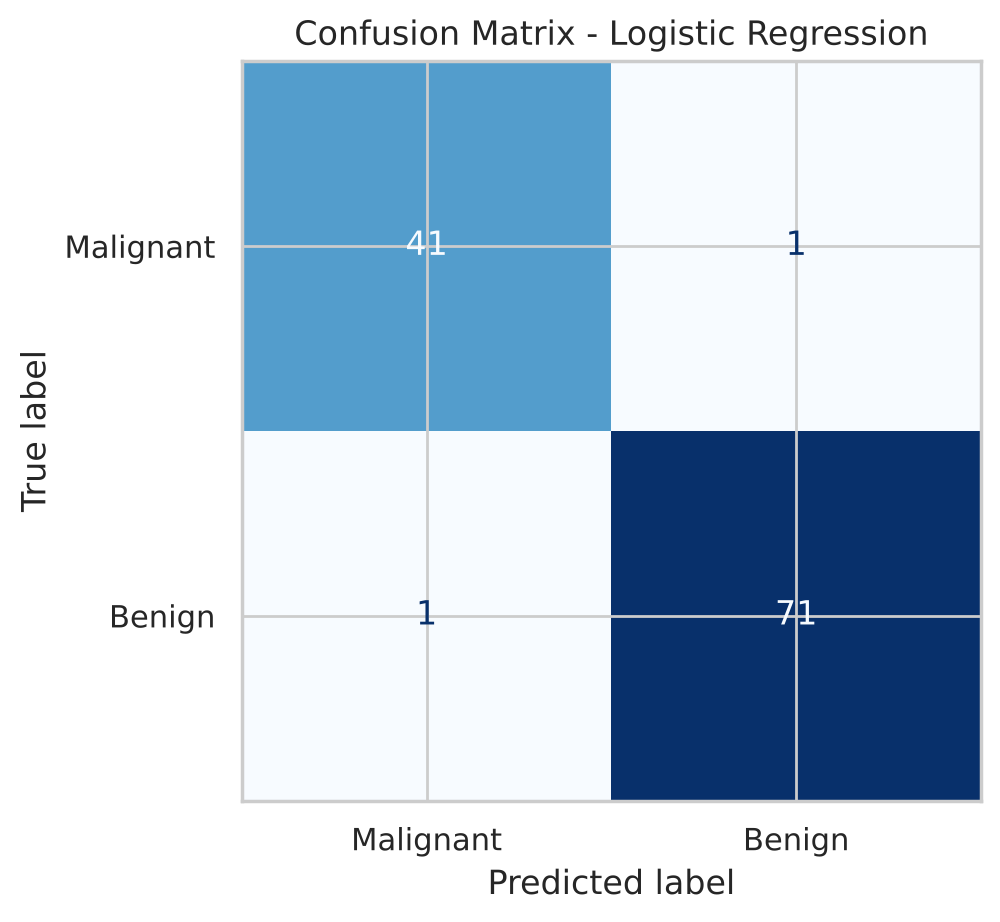

In [5]:
cm = confusion_matrix(yc_test, yc_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix:")
print(cm)
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

# Check: the metrics calculated by hand from the confusion matrix match scikit-learn
print()
print("Accuracy  by hand:", round((tp + tn) / cm.sum(), 4))
print("Precision by hand:", round(tp / (tp + fp), 4))
print("Recall    by hand:", round(tp / (tp + fn), 4))

ConfusionMatrixDisplay(cm, display_labels=["Malignant", "Benign"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [6]:
print(classification_report(yc_test, yc_pred, target_names=["Malignant", "Benign"]))

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Question 2: Regression model and its evaluation metrics

| Metric | Formula | Meaning |
|---|---|---|
| MAE | mean(abs(y − ŷ)) | Average size of the errors, in the units of the target |
| MSE | mean((y − ŷ)²) | Average squared error; punishes large errors more |
| RMSE | √MSE | Typical error, in the units of the target |
| R² score | 1 − SS_residual / SS_total | Share of the variation in the target explained by the model (1 = perfect, 0 = no better than predicting the mean) |

In [7]:
diabetes = load_diabetes()
X_r = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y_r = pd.Series(diabetes.target)

print("Shape:", X_r.shape)
print(y_r.describe().round(2))

Shape: (442, 10)
count    442.00
mean     152.13
std       77.09
min       25.00
25%       87.00
50%      140.50
75%      211.50
max      346.00
dtype: float64


In [8]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_r, test_size=0.2, random_state=42)

reg = LinearRegression()
reg.fit(Xr_train, yr_train)
yr_pred = reg.predict(Xr_test)

mae  = mean_absolute_error(yr_test, yr_pred)
mse  = mean_squared_error(yr_test, yr_pred)
rmse = np.sqrt(mse)
r2   = r2_score(yr_test, yr_pred)

print(f"MAE      : {mae:.4f}")
print(f"MSE      : {mse:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"R2 score : {r2:.4f}")

# Check by hand with NumPy
err = yr_test.values - yr_pred
print()
print("MAE  by hand:", round(np.mean(np.abs(err)), 4))
print("MSE  by hand:", round(np.mean(err ** 2), 4))
print("R2   by hand:", round(1 - np.sum(err ** 2) / np.sum((yr_test - yr_test.mean()) ** 2), 4))

MAE      : 42.7941
MSE      : 2900.1936
RMSE     : 53.8534
R2 score : 0.4526

MAE  by hand: 42.7941
MSE  by hand: 2900.1936
R2   by hand: 0.4526


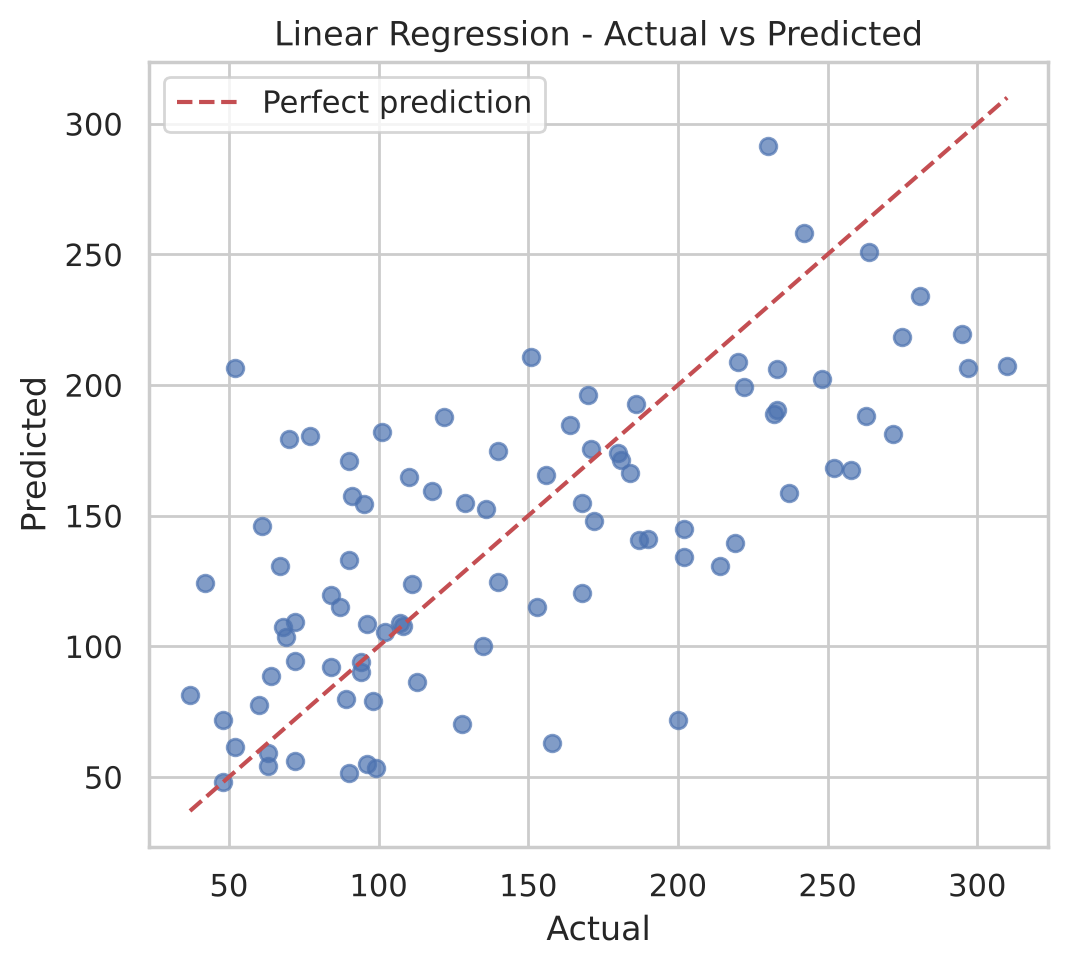

In [9]:
plt.figure(figsize=(5.5, 5))
plt.scatter(yr_test, yr_pred, alpha=0.7)
lims = [yr_test.min(), yr_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Linear Regression - Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## Question 3: Which metric is more suitable for an imbalanced classification dataset?

On an imbalanced dataset, **accuracy is misleading**, because a model that always predicts the majority class still gets a high accuracy. The demonstration below uses a dataset with 95% negative and 5% positive cases.

In [10]:
X_i, y_i = make_classification(n_samples=5000, n_features=10, n_informative=5,
                               weights=[0.95, 0.05], flip_y=0.02, class_sep=2.0, random_state=42)
print("Class counts:", np.bincount(y_i), f"(positive class = {y_i.mean()*100:.1f}%)")

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_i, y_i, test_size=0.25, random_state=42, stratify=y_i)

models = {
    "Always predicts majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
rows = []
for name, m in models.items():
    m.fit(Xi_train, yi_train)
    p = m.predict(Xi_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(yi_test, p),
                 "Precision": precision_score(yi_test, p, zero_division=0),
                 "Recall": recall_score(yi_test, p),
                 "F1-score": f1_score(yi_test, p)})
pd.DataFrame(rows).set_index("Model").round(4)

Class counts: [4703  297] (positive class = 5.9%)


,Accuracy,Precision,Recall,F1-score
Model,,,,
Always predicts majority class,0.9408,0.0000,0.0000,0.0000
Logistic Regression,0.9688,0.8889,0.5405,0.6723


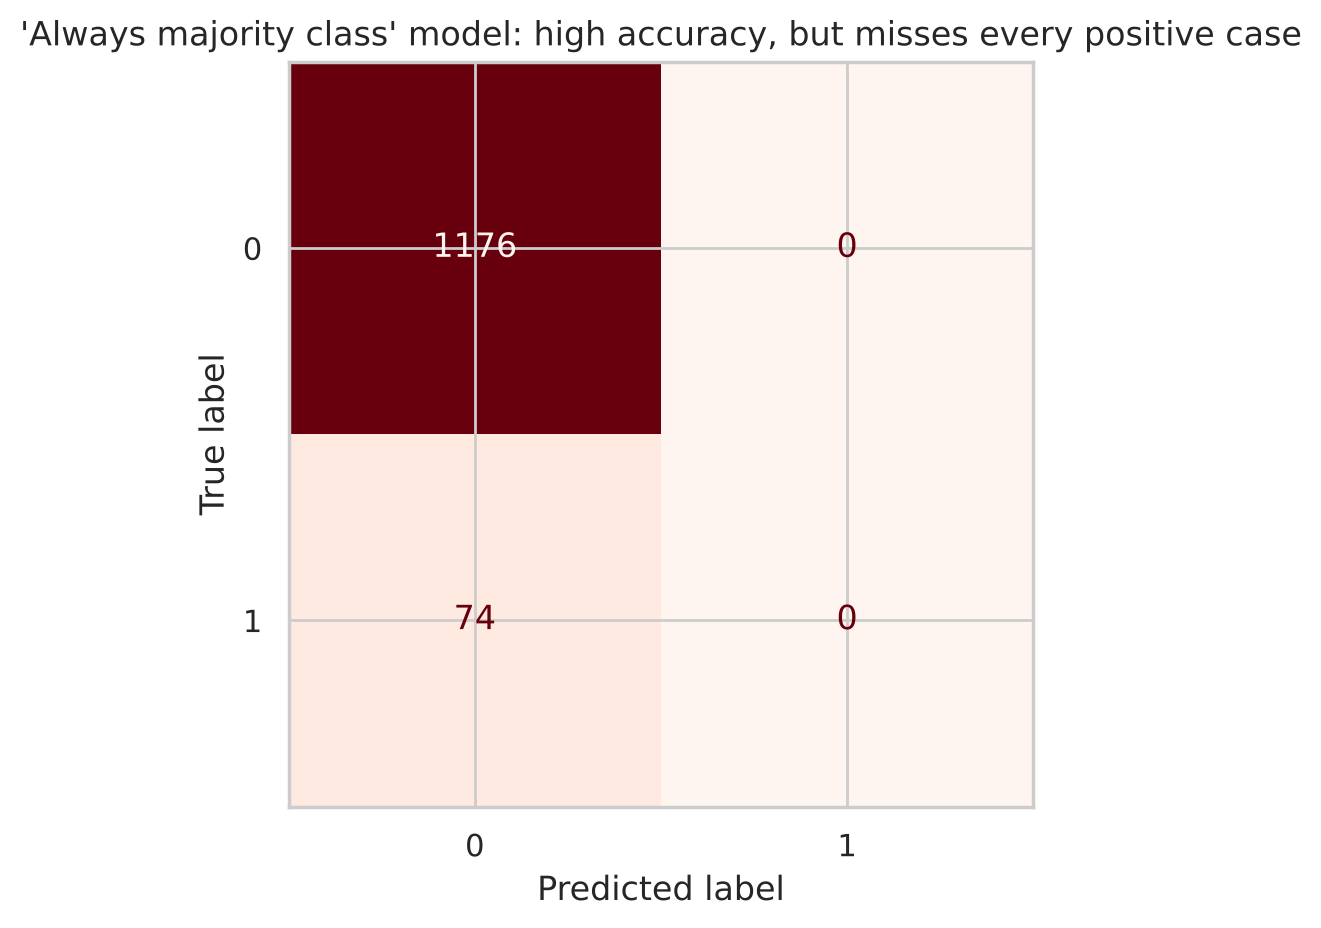

In [11]:
ConfusionMatrixDisplay.from_predictions(yi_test, models["Always predicts majority class"].predict(Xi_test),
                                        cmap="Reds", colorbar=False)
plt.title("'Always majority class' model: high accuracy, but misses every positive case")
plt.tight_layout()
plt.show()

**Answer: the F1-score (together with precision and recall) is more suitable than accuracy.**

The results above show why:

- A model that **always predicts the majority class** reaches **94.1% accuracy** but has **0 recall and 0 F1-score**, because it never finds a single positive case.
- The Logistic Regression model reaches **96.9% accuracy**, which looks excellent, but its recall is only **54%**, so it still misses almost half of the positive cases. Accuracy hides this, while recall and F1-score show it.

Which metric to prefer depends on the cost of each type of error:

| Situation | Best metric |
|---|---|
| Missing a positive case is costly (disease, fraud, churn) | **Recall** |
| A false alarm is costly (spam filter blocking real email) | **Precision** |
| Both matter and a single number is needed | **F1-score** (balance of precision and recall) |

The confusion matrix should always be checked as well, because it shows exactly which kinds of mistakes the model makes.

## Question 4: Compare the evaluation results of the classification and regression models

In [12]:
summary = pd.DataFrame({
    "Classification (Logistic Regression)": {
        "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1,
    },
    "Regression (Linear Regression)": {
        "MAE": mae, "MSE": mse, "RMSE": rmse, "R2 score": r2,
    },
})
print("Classification metrics:")
print(pd.Series({"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}).round(4).to_string())
print()
print("Regression metrics:")
print(pd.Series({"MAE": mae, "MSE": mse, "RMSE": rmse, "R2 score": r2}).round(4).to_string())
print()
print(f"Target standard deviation (regression): {yr_test.std():.2f}  vs  RMSE: {rmse:.2f}")
baseline_r2 = r2_score(yr_test, np.full(len(yr_test), yr_train.mean()))
print(f"Baseline (always predict the training mean) R2: {baseline_r2:.4f}  vs  model R2: {r2:.4f}")

Classification metrics:
Accuracy     0.9825
Precision    0.9861
Recall       0.9861
F1-score     0.9861

Regression metrics:
MAE           42.7941
MSE         2900.1936
RMSE          53.8534
R2 score       0.4526

Target standard deviation (regression): 73.20  vs  RMSE: 53.85
Baseline (always predict the training mean) R2: -0.0120  vs  model R2: 0.4526


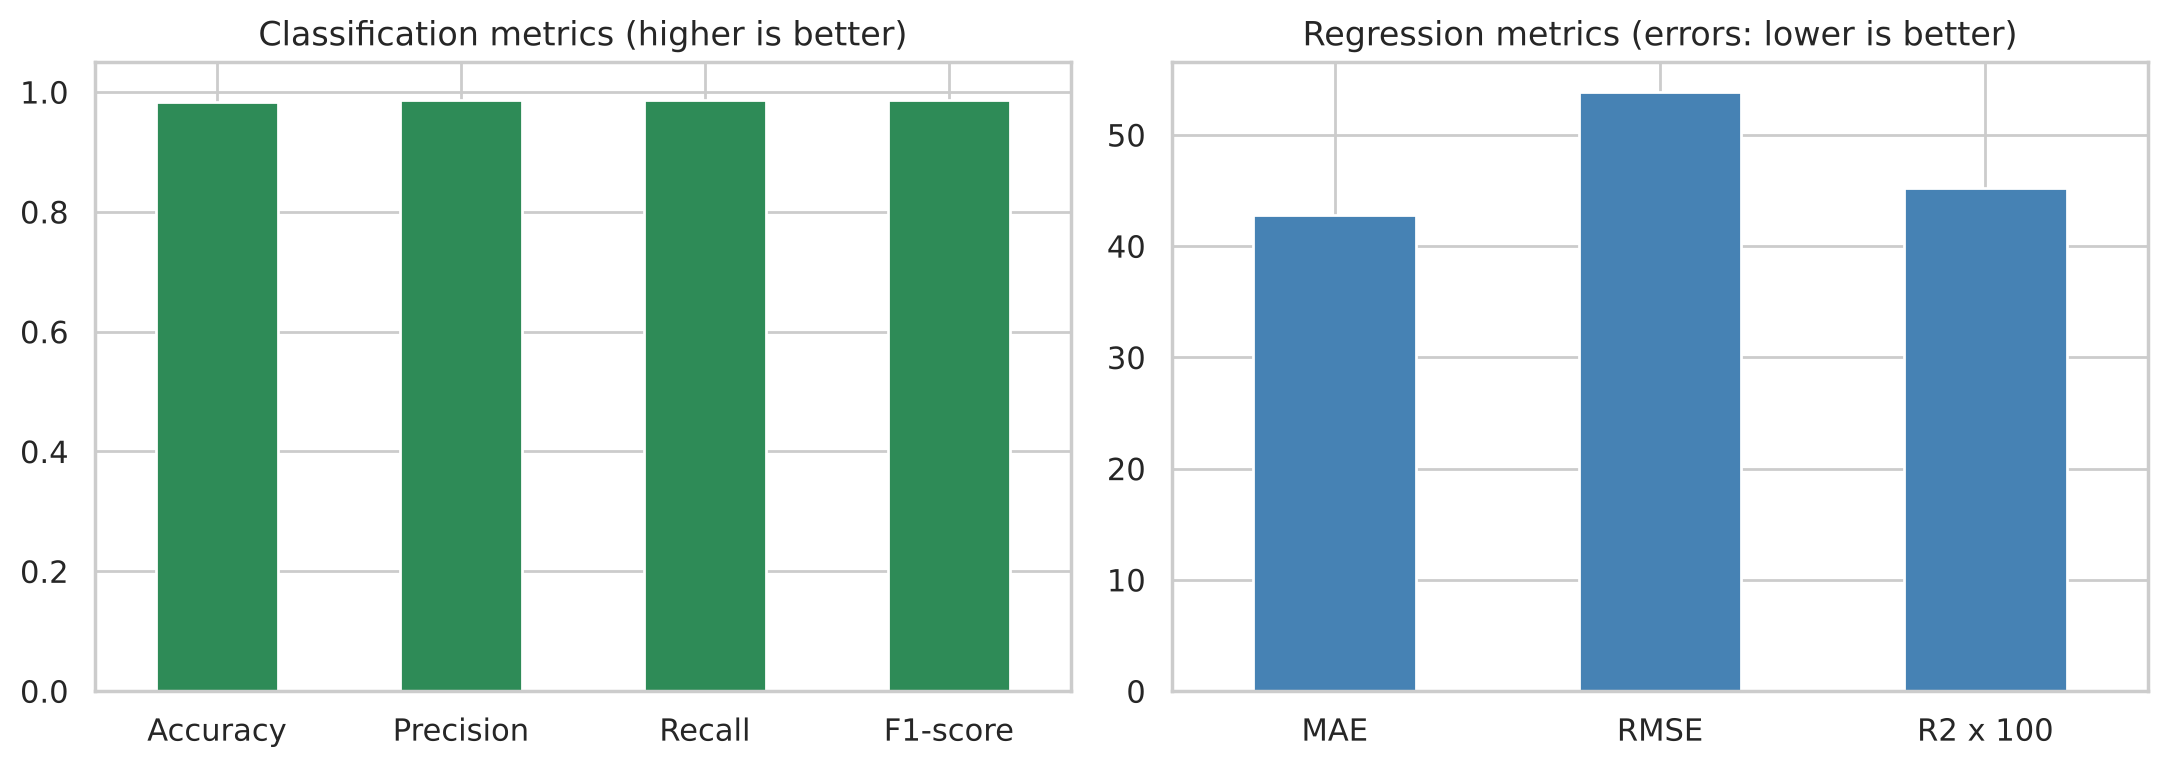

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pd.Series({"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}).plot(
    kind="bar", ax=axes[0], color="seagreen", rot=0)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Classification metrics (higher is better)")

pd.Series({"MAE": mae, "RMSE": rmse, "R2 x 100": r2 * 100}).plot(
    kind="bar", ax=axes[1], color="steelblue", rot=0)
axes[1].set_title("Regression metrics (errors: lower is better)")
plt.tight_layout()
plt.show()

## Comparison and conclusion

The two models solve different problems, so their numbers cannot be compared directly: classification metrics count correct and wrong labels, while regression metrics measure how far a predicted number is from the real number. Two different datasets were also used, so the differences below reflect the data as much as the models. They can still be compared by how well each model does its job.

| | Classification (Logistic Regression) | Regression (Linear Regression) |
|---|---|---|
| Task | Predict malignant or benign | Predict a disease progression score |
| Metrics | Accuracy, Precision, Recall, F1, Confusion Matrix | MAE, MSE, RMSE, R² |
| Scale | 0 to 1, **higher is better** | MAE, MSE and RMSE: **lower is better**, in the units of the target (MSE in squared units). R²: higher is better |
| Result | Accuracy 0.983, F1 0.986 | R² 0.453, MAE 42.8, RMSE 53.9 |
| Quality | **Very strong**: only 2 mistakes out of 114 patients (1 false positive, 1 false negative) | **Moderate**: explains about 45% of the variation in the target |

- **Classification:** The model is almost perfect on this dataset. Precision and recall are both 0.986, so it is not trading one for the other.
- **Regression:** The typical error (RMSE of about 54) is large compared with the spread of the target (standard deviation of about 73). The model is clearly better than simply predicting the mean (R² of 0.45 compared with about 0 for that baseline), but far from exact. RMSE is higher than MAE because a few predictions have large errors, which RMSE punishes more.
- **Why the difference:** The breast cancer measurements separate the two classes very well. The diabetes progression score depends on factors that are not in the 10 available features, and a linear model cannot capture every pattern, so a large part of the variation stays unexplained.